# Real Estate Machine
## 1. Import Libraries and Load Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

df = pd.read_csv('/content/house_prices (1).csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,N,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,N,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,N,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,N,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,N,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. Data Understanding

In [ ]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  object 
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  object 
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [ ]:
missing = df.isnull().sum()
print(missing)

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df.shape)

(21613, 21)


In [ ]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.234303,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.766318,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,4.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


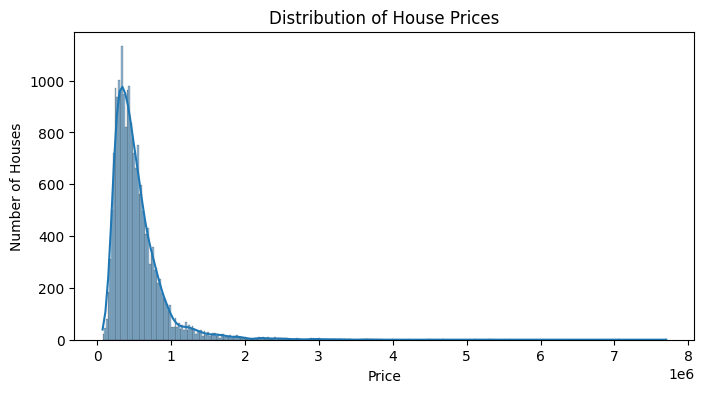

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(df['price'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.ylabel('Number of Houses')

plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv('/content/house_prices (1).csv')

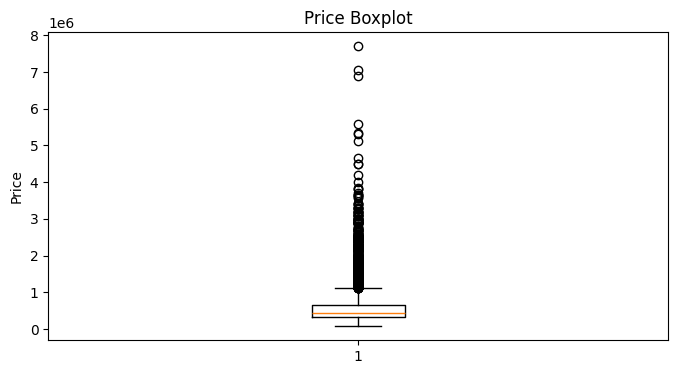

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(df['price'])
plt.title('Price Boxplot')
plt.ylabel('Price')
plt.show()

## 3. Data Cleaning

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)

Q1 = 321950.0
Q3 = 645000.0
IQR = 323050.0
Lower Bound = -162625.0
Upper Bound = 1129575.0


In [ ]:
outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

print("Number of price outliers:", len(outliers))

Number of price outliers: 1146


In [ ]:
df['waterfront'].value_counts()

,count
waterfront,
N,21450
Y,163


In [ ]:
df['condition'].value_counts()

,count
condition,
Average,14031
Good,5679
Very Good,1701
Fair,172
Poor,30


In [ ]:
df['date'] = pd.to_datetime(df['date'])

In [ ]:
df['date'].dtype

dtype('<M8[ns]')

In [ ]:
df['sale_year'] = df['date'].dt.year

In [ ]:
df['sale_month'] = df['date'].dt.month

In [ ]:
df[['date', 'sale_year', 'sale_month']].head()

,date,sale_year,sale_month
0,2014-10-13,2014,10
1,2014-12-09,2014,12
2,2015-02-25,2015,2
3,2014-12-09,2014,12
4,2015-02-18,2015,2


In [ ]:
df['waterfront'] = df['waterfront'].map({'N': 0, 'Y': 1})

In [ ]:
df['waterfront'].value_counts()

,count
waterfront,
0,21450
1,163


In [ ]:
df['condition'] = df['condition'].map({
    'Poor': 1,
    'Fair': 2,
    'Average': 3,
    'Good': 4,
    'Very Good': 5
})

In [ ]:
df['condition'].value_counts().sort_index()

,count
condition,
1,30
2,172
3,14031
4,5679
5,1701


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[ns]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   waterfront     21613 non-null  int64         
 9   view           21613 non-null  int64         
 10  condition      21613 non-null  int64         
 11  grade          21613 non-null  int64         
 12  sqft_above     21613 non-null  int64         
 13  sqft_basement  21613 non-null  int64         
 14  yr_built       21613 non-null  int64         
 15  yr_renovated   2161

In [ ]:
df[df['bedrooms'] == 33]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month
15870,2402100895,2014-06-25,640000.0,33,1.75,1620,6000,1.0,0,0,...,580,1947,0,98103,47.6878,-122.331,1330,4700,2014,6


In [ ]:
df[df['bedrooms'] == 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month
875,6306400140,2014-06-12,1095000.0,0,0.00,3064,4764,3.5,0,2,...,0,1990,0,98102,47.6362,-122.322,2360,4000,2014,6
3119,3918400017,2015-02-05,380000.0,0,0.00,1470,979,3.0,0,2,...,0,2006,0,98133,47.7145,-122.356,1470,1399,2015,2
3467,1453602309,2014-08-05,288000.0,0,1.50,1430,1650,3.0,0,0,...,0,1999,0,98125,47.7222,-122.290,1430,1650,2014,8
4868,6896300380,2014-10-02,228000.0,0,1.00,390,5900,1.0,0,0,...,0,1953,0,98118,47.5260,-122.261,2170,6000,2014,10
6994,2954400190,2014-06-24,1295650.0,0,0.00,4810,28008,2.0,0,0,...,0,1990,0,98053,47.6642,-122.069,4740,35061,2014,6
8477,2569500210,2014-11-17,339950.0,0,2.50,2290,8319,2.0,0,0,...,0,1985,0,98042,47.3473,-122.151,2500,8751,2014,11
8484,2310060040,2014-09-25,240000.0,0,2.50,1810,5669,2.0,0,0,...,0,2003,0,98038,47.3493,-122.053,1810,5685,2014,9
9773,3374500520,2015-04-29,355000.0,0,0.00,2460,8049,2.0,0,0,...,0,1990,0,98031,47.4095,-122.168,2520,8050,2015,4
9854,7849202190,2014-12-23,235000.0,0,0.00,1470,4800,2.0,0,0,...,0,1996,0,98065,47.5265,-121.828,1060,7200,2014,12
12653,7849202299,2015-02-18,320000.0,0,2.50,1490,7111,2.0,0,0,...,0,1999,0,98065,47.5261,-121.826,1500,4675,2015,2


In [ ]:
df[df['bathrooms'] == 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month
875,6306400140,2014-06-12,1095000.0,0,0.0,3064,4764,3.5,0,2,...,0,1990,0,98102,47.6362,-122.322,2360,4000,2014,6
1149,3421079032,2015-02-17,75000.0,1,0.0,670,43377,1.0,0,0,...,0,1966,0,98022,47.2638,-121.906,1160,42882,2015,2
3119,3918400017,2015-02-05,380000.0,0,0.0,1470,979,3.0,0,2,...,0,2006,0,98133,47.7145,-122.356,1470,1399,2015,2
5832,5702500050,2014-11-04,280000.0,1,0.0,600,24501,1.0,0,0,...,0,1950,0,98045,47.5316,-121.749,990,22549,2014,11
6994,2954400190,2014-06-24,1295650.0,0,0.0,4810,28008,2.0,0,0,...,0,1990,0,98053,47.6642,-122.069,4740,35061,2014,6
9773,3374500520,2015-04-29,355000.0,0,0.0,2460,8049,2.0,0,0,...,0,1990,0,98031,47.4095,-122.168,2520,8050,2015,4
9854,7849202190,2014-12-23,235000.0,0,0.0,1470,4800,2.0,0,0,...,0,1996,0,98065,47.5265,-121.828,1060,7200,2014,12
10481,203100435,2014-09-18,484000.0,1,0.0,690,23244,1.0,0,0,...,0,1948,0,98053,47.6429,-121.955,1690,19290,2014,9
14423,9543000205,2015-04-13,139950.0,0,0.0,844,4269,1.0,0,0,...,0,1913,0,98001,47.2781,-122.250,1380,9600,2015,4
19452,3980300371,2014-09-26,142000.0,0,0.0,290,20875,1.0,0,0,...,0,1963,0,98024,47.5308,-121.888,1620,22850,2014,9


In [ ]:
df[df['bedrooms'] == 33]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month
15870,2402100895,2014-06-25,640000.0,33,1.75,1620,6000,1.0,0,0,...,580,1947,0,98103,47.6878,-122.331,1330,4700,2014,6


In [ ]:
df[df['bedrooms'] == 33][[
    'price',
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'grade',
    'condition'
]]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,grade,condition
15870,640000.0,33,1.75,1620,6000,1.0,7,5


In [ ]:
df['bedrooms'].value_counts().sort_index()

,count
bedrooms,
0,13
1,199
2,2760
3,9824
4,6882
5,1601
6,272
7,38
8,13


In [ ]:
df.loc[df['bedrooms'] == 33, 'bedrooms'] = 3

In [ ]:
df['bedrooms'].value_counts().sort_index()

,count
bedrooms,
0,13
1,199
2,2760
3,9825
4,6882
5,1601
6,272
7,38
8,13


In [ ]:
df[df['bathrooms'] == 0][[
    'price',
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'grade',
    'condition'
]]

,price,bedrooms,bathrooms,sqft_living,grade,condition
875,1095000.0,0,0.0,3064,7,3
1149,75000.0,1,0.0,670,3,3
3119,380000.0,0,0.0,1470,8,3
5832,280000.0,1,0.0,600,3,2
6994,1295650.0,0,0.0,4810,12,3
9773,355000.0,0,0.0,2460,8,3
9854,235000.0,0,0.0,1470,7,3
10481,484000.0,1,0.0,690,7,4
14423,139950.0,0,0.0,844,7,4
19452,142000.0,0,0.0,290,1,1


In [ ]:
corr = df.select_dtypes(include='number').corr()['price'].sort_values(ascending=False)

print(corr)

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.315438
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
sale_year        0.003576
sale_month      -0.010081
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64


In [ ]:
import seaborn as sns

## 4. Exploratory Data Analysis (EDA)

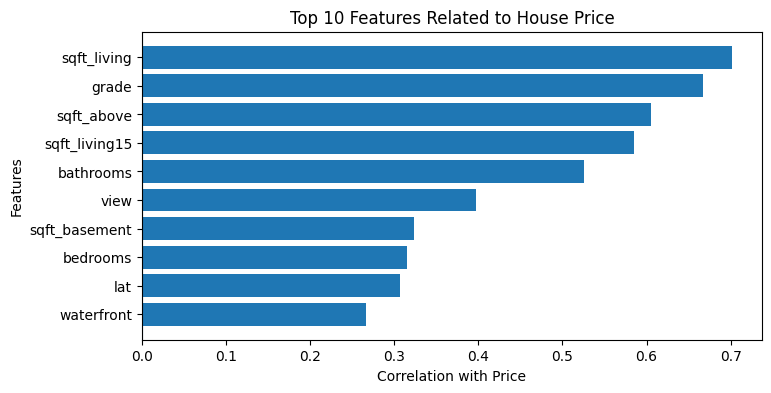

In [ ]:
corr_with_price = (
    df.select_dtypes(include='number')
      .corr()['price']
      .drop('price')
      .abs()
      .sort_values(ascending=False)
      .head(10)
)

# Get original correlation values
top_features = (
    df.select_dtypes(include='number')
      .corr()['price']
      .loc[corr_with_price.index]
      .sort_values()
)

plt.figure(figsize=(8, 4))

plt.barh(top_features.index, top_features.values)

plt.title('Top 10 Features Related to House Price')
plt.xlabel('Correlation with Price')
plt.ylabel('Features')

plt.axvline(0)

plt.show()

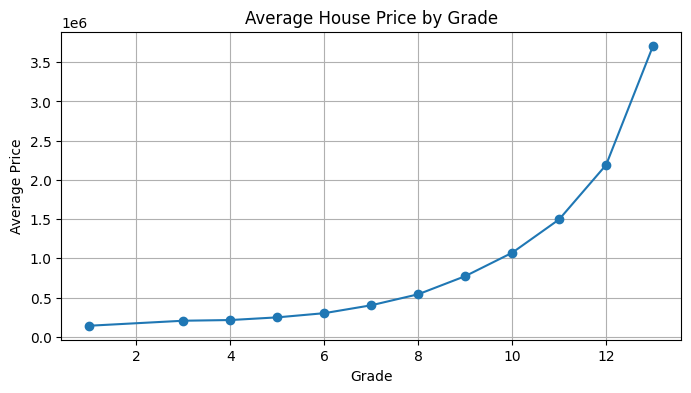

In [ ]:
grade_price = df.groupby('grade')['price'].mean()

plt.figure(figsize=(8, 4))

plt.plot(grade_price.index, grade_price.values, marker='o')

plt.title('Average House Price by Grade')
plt.xlabel('Grade')
plt.ylabel('Average Price')

plt.grid(True)

plt.show()

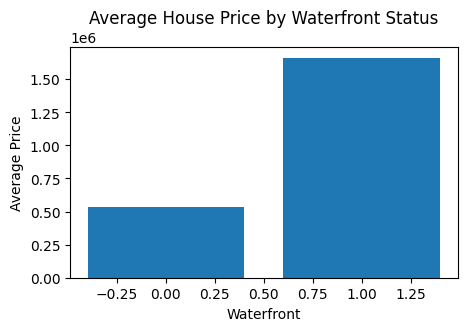

In [ ]:
waterfront_price = df.groupby('waterfront')['price'].mean()

plt.figure(figsize=(5, 3))

plt.bar(waterfront_price.index, waterfront_price.values)

plt.title('Average House Price by Waterfront Status')
plt.xlabel('Waterfront')
plt.ylabel('Average Price')

plt.show()

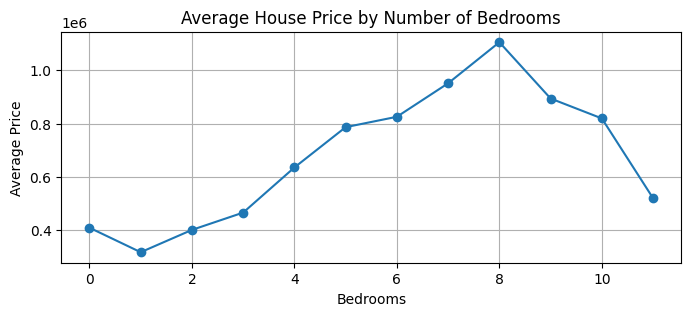

In [ ]:
bedroom_price = df.groupby('bedrooms')['price'].mean()

plt.figure(figsize=(8, 3))

plt.plot(bedroom_price.index, bedroom_price.values, marker='o')

plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('Average Price')

plt.grid(True)

plt.show()

In [ ]:
df['living_area_group'] = pd.cut(
    df['sqft_living'],
    bins=[0, 1000, 1500, 2000, 2500, 3000, 4000, 6000, 14000],
    labels=[
        '0-1000',
        '1001-1500',
        '1501-2000',
        '2001-2500',
        '2501-3000',
        '3001-4000',
        '4001-6000',
        '6001+'
    ]
)

In [ ]:
area_price = df.groupby(
    'living_area_group',
    observed=True
)['price'].mean()

print(area_price)

living_area_group
0-1000       2.983010e+05
1001-1500    3.612521e+05
1501-2000    4.325443e+05
2001-2500    5.311568e+05
2501-3000    6.567265e+05
3001-4000    8.727551e+05
4001-6000    1.417693e+06
6001+        2.674372e+06
Name: price, dtype: float64


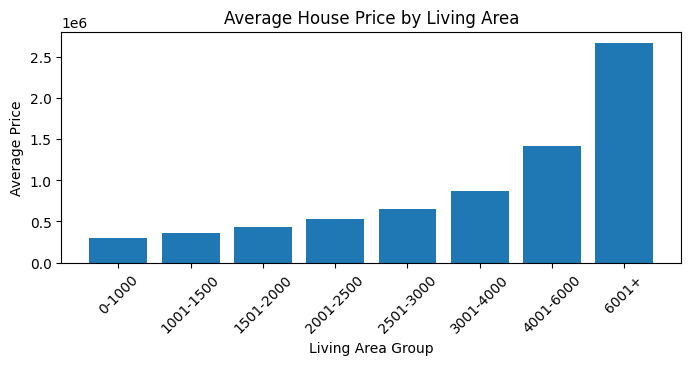

In [ ]:
plt.figure(figsize=(8, 3))

plt.bar(area_price.index, area_price.values)

plt.title('Average House Price by Living Area')
plt.xlabel('Living Area Group')
plt.ylabel('Average Price')

plt.xticks(rotation=45)

plt.show()

In [ ]:
condition_price = df.groupby('condition')['price'].mean()

print(condition_price)

condition
1    334431.666667
2    327287.145349
3    542012.578148
4    521200.390033
5    612418.089359
Name: price, dtype: float64


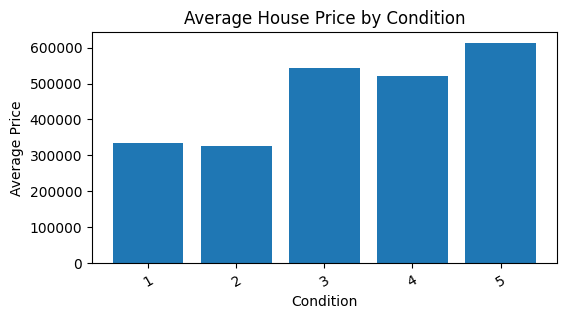

In [ ]:
plt.figure(figsize=(6, 3))

plt.bar(condition_price.index, condition_price.values)

plt.title('Average House Price by Condition')
plt.xlabel('Condition')
plt.ylabel('Average Price')

plt.xticks(rotation=30)

plt.show()

In [ ]:
year_price = df.groupby('sale_year')['price'].mean()

print(year_price)

sale_year
2014    539181.428415
2015    541988.992264
Name: price, dtype: float64


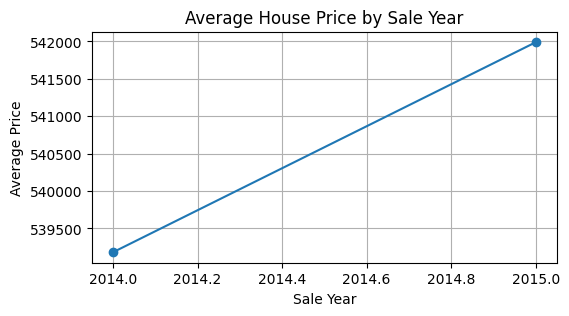

In [ ]:
plt.figure(figsize=(6, 3))

plt.plot(year_price.index, year_price.values, marker='o')

plt.title('Average House Price by Sale Year')
plt.xlabel('Sale Year')
plt.ylabel('Average Price')

plt.grid(True)

plt.show()

## 5. Business Insights


### Key Findings

- Living area (`sqft_living`) has the strongest positive correlation with house price among the main numerical features.
- Construction/architecture grade (`grade`) is also strongly associated with higher house prices.
- Waterfront properties have a much higher average price than non-waterfront properties in this dataset.
- The average house price changes only slightly between the two sale years available in the dataset.

## 6. Unsupervised Learning - Clustering

In [ ]:
cluster_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'zipcode',
    'lat',
    'long',
    'sqft_living15',
    'sqft_lot15'
]

X_cluster = df[cluster_features]

print("Clustering data shape:", X_cluster.shape)

Clustering data shape: (21613, 18)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (21613, 18)


In [ ]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

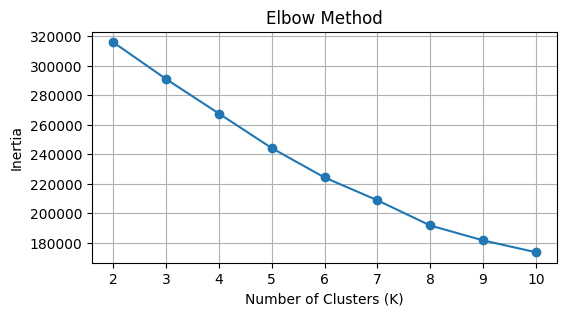

In [ ]:
plt.figure(figsize=(6, 3))

plt.plot(range(2, 11), inertia, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.grid(True)
plt.show()

In [ ]:
import numpy as np

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import numpy as np

silhouette_scores = []

sample_size = min(3000, len(X_scaled))

sample_indices = np.random.RandomState(42).choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled[sample_indices]

for k in range(2, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    sample_labels = labels[sample_indices]

    score = silhouette_score(
        X_sample,
        sample_labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2167
K = 3, Silhouette Score = 0.1279
K = 4, Silhouette Score = 0.1365
K = 5, Silhouette Score = 0.1437
K = 6, Silhouette Score = 0.1533
K = 7, Silhouette Score = 0.1494


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

In [ ]:
df['cluster'] = cluster_labels

In [ ]:
cluster_profile = df.groupby('cluster')[
    [
        'bedrooms',
        'bathrooms',
        'sqft_living',
        'grade',
        'condition',
        'waterfront',
        'price'
    ]
].mean()

print(cluster_profile)

         bedrooms  bathrooms  sqft_living     grade  condition  waterfront  \
cluster                                                                      
0        3.066892   1.722799  1591.136193  7.051919   3.523025    0.003236   
1        3.852577   2.740628  2860.347591  8.622852   3.228043    0.014418   

                 price  
cluster                 
0        416961.647028  
1        736694.066923  


In [ ]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

df['cluster'] = cluster_labels

In [ ]:
cluster_profile = df.groupby('cluster')[
    [
        'bedrooms',
        'bathrooms',
        'sqft_living',
        'grade',
        'condition',
        'waterfront',
        'price'
    ]
].mean()

print(cluster_profile)

         bedrooms  bathrooms  sqft_living     grade  condition  waterfront  \
cluster                                                                      
0        3.066892   1.722799  1591.136193  7.051919   3.523025    0.003236   
1        3.852577   2.740628  2860.347591  8.622852   3.228043    0.014418   

                 price  
cluster                 
0        416961.647028  
1        736694.066923  


In [ ]:
df['category'] = df['cluster'].map({
    0: 'Standard Properties',
    1: 'Premium Properties'
})

In [ ]:
df[['cluster', 'category']].head()

,cluster,category
0,0,Standard Properties
1,0,Standard Properties
2,0,Standard Properties
3,0,Standard Properties
4,0,Standard Properties


In [ ]:
df['category'].value_counts()

,count
category,
Standard Properties,13290
Premium Properties,8323


## 7. Category Classification

In [4]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv('/content/house_prices (1).csv')

# Correct the unusual bedroom value
df.loc[df['bedrooms'] == 33, 'bedrooms'] = 3

# Convert date
df['date'] = pd.to_datetime(df['date'])
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month

# Encode waterfront
df['waterfront'] = df['waterfront'].map({
    'N': 0,
    'Y': 1
})

# Encode condition
df['condition'] = df['condition'].map({
    'Poor': 1,
    'Fair': 2,
    'Average': 3,
    'Good': 4,
    'Very Good': 5
})

# Clustering features
cluster_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'zipcode',
    'lat',
    'long',
    'sqft_living15',
    'sqft_lot15'
]

X_cluster = df[cluster_features]

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X_scaled)

# Create categories
df['category'] = df['cluster'].map({
    0: 'Standard Properties',
    1: 'Premium Properties'
})

print(df.shape)
print(df['category'].value_counts())

(21613, 25)
category
Standard Properties    13290
Premium Properties      8323
Name: count, dtype: int64


In [5]:
classification_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'zipcode',
    'lat',
    'long',
    'sqft_living15',
    'sqft_lot15'
]

X = df[classification_features]
y = df['category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (21613, 18)
y shape: (21613,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (17290, 18)
X_test: (4323, 18)


In [11]:
from sklearn.preprocessing import StandardScaler

classification_scaler = StandardScaler()

X_train_scaled = classification_scaler.fit_transform(X_train)
X_test_scaled = classification_scaler.transform(X_test)

In [12]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

In [13]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.9988433957899607


In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_logistic))

                     precision    recall  f1-score   support

 Premium Properties       1.00      1.00      1.00      1665
Standard Properties       1.00      1.00      1.00      2658

           accuracy                           1.00      4323
          macro avg       1.00      1.00      1.00      4323
       weighted avg       1.00      1.00      1.00      4323



In [18]:
import matplotlib.pyplot as plt

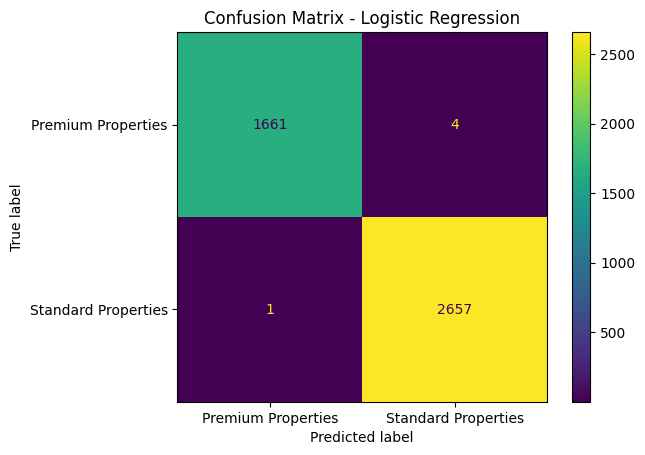

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

disp.plot()

plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9777931991672449

Classification Report:
                     precision    recall  f1-score   support

 Premium Properties       0.98      0.96      0.97      1665
Standard Properties       0.98      0.99      0.98      2658

           accuracy                           0.98      4323
          macro avg       0.98      0.98      0.98      4323
       weighted avg       0.98      0.98      0.98      4323



In [21]:
print("Logistic Regression Accuracy:", accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Logistic Regression Accuracy: 0.9988433957899607
Random Forest Accuracy: 0.9777931991672449


In [22]:
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report:
                     precision    recall  f1-score   support

 Premium Properties       0.98      0.96      0.97      1665
Standard Properties       0.98      0.99      0.98      2658

           accuracy                           0.98      4323
          macro avg       0.98      0.98      0.98      4323
       weighted avg       0.98      0.98      0.98      4323



In [23]:
import joblib

classification_package = {
    'model': logistic_model,
    'scaler': classification_scaler,
    'features': classification_features
}

joblib.dump(
    classification_package,
    'classification_model.joblib'
)

print("Classification model saved successfully.")

Classification model saved successfully.


## 8. Price Regression

In [24]:
regression_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'zipcode',
    'lat',
    'long',
    'sqft_living15',
    'sqft_lot15'
]

X_reg = df[regression_features]
y_reg = df['price']

print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)

X shape: (21613, 18)
y shape: (21613,)


In [25]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (17290, 18)
Testing data: (4323, 18)


In [26]:
from sklearn.preprocessing import StandardScaler

regression_scaler = StandardScaler()

X_train_reg_scaled = regression_scaler.fit_transform(X_train_reg)
X_test_reg_scaled = regression_scaler.transform(X_test_reg)


In [27]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_reg_scaled, y_train_reg)

y_pred_linear = linear_model.predict(X_test_reg_scaled)

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test_reg, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test_reg, y_pred_linear))
r2_linear = r2_score(y_test_reg, y_pred_linear)

print("Linear Regression Results")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Results
MAE : 127532.88799645846
RMSE: 212495.8267157325
R²  : 0.7013132796876614


In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_reg_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_reg_model.fit(X_train_reg, y_train_reg)

y_pred_rf_reg = rf_reg_model.predict(X_test_reg)

mae_rf = mean_absolute_error(y_test_reg, y_pred_rf_reg)
rmse_rf = np.sqrt(mean_squared_error(y_test_reg, y_pred_rf_reg))
r2_rf = r2_score(y_test_reg, y_pred_rf_reg)

print("Random Forest Regression Results")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression Results
MAE : 72596.53998282534
RMSE: 146488.4125413752
R²  : 0.858054493390275


In [35]:
feature_importance = pd.Series(
    rf_reg_model.feature_importances_,
    index=X_train_reg.columns
).sort_values(ascending=False)

print(feature_importance)

grade            0.317728
sqft_living      0.270935
lat              0.153499
long             0.062671
yr_built         0.034008
waterfront       0.031604
sqft_living15    0.031055
sqft_above       0.018717
zipcode          0.014487
sqft_lot         0.013827
sqft_lot15       0.012903
bathrooms        0.012240
view             0.009916
sqft_basement    0.006413
bedrooms         0.002958
condition        0.002930
yr_renovated     0.002161
floors           0.001948
dtype: float64


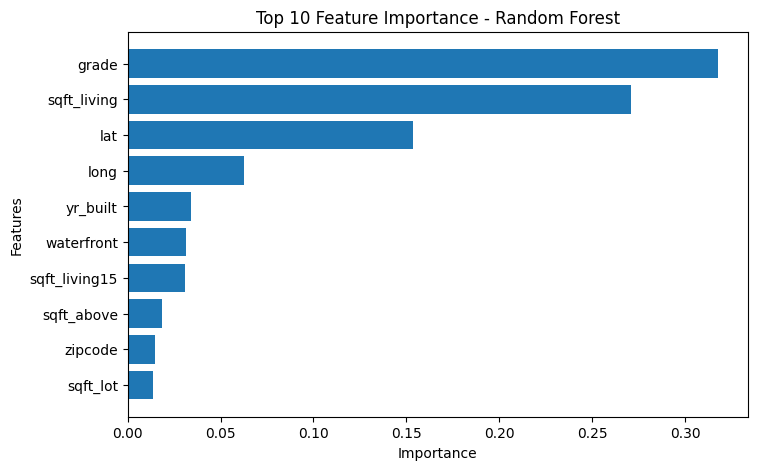

In [37]:
plt.figure(figsize=(8, 5))

top_features = feature_importance.head(10).sort_values()

plt.barh(top_features.index, top_features.values)

plt.title('Top 10 Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

In [38]:
print("Number of model features:", len(rf_reg_model.feature_importances_))
print("Number of feature names:", len(regression_features))

Number of model features: 18
Number of feature names: 1


In [39]:
import joblib

regression_package = {
    'model': rf_reg_model,
    'features': regression_features
}

joblib.dump(
    regression_package,
    'regression_model.joblib'
)

print("Regression model saved successfully.")

Regression model saved successfully.


## 9. LLM-Based Model Interpretation

In [42]:
sample_index = X_test_reg.index[0]

sample_house = X_test_reg.loc[sample_index]

actual_price = y_test_reg.loc[sample_index]

predicted_price = rf_reg_model.predict(
    X_test_reg.loc[[sample_index]]
)[0]

print("Actual Price:", actual_price)
print("Predicted Price:", predicted_price)

print("\nHouse Features:")
print(sample_house)

Actual Price: 365000.0
Predicted Price: 377278.0

House Features:
bedrooms             4.0000
bathrooms            2.2500
sqft_living       2070.0000
sqft_lot          8893.0000
floors               2.0000
waterfront           0.0000
view                 0.0000
condition            4.0000
grade                8.0000
sqft_above        2070.0000
sqft_basement        0.0000
yr_built          1986.0000
yr_renovated         0.0000
zipcode          98058.0000
lat                 47.4388
long              -122.1620
sqft_living15     2390.0000
sqft_lot15        7700.0000
Name: 735, dtype: float64


In [43]:
top_5_features = feature_importance.head(5)

print("Top 5 Important Features:")
print(top_5_features)

Top 5 Important Features:
grade          0.317728
sqft_living    0.270935
lat            0.153499
long           0.062671
yr_built       0.034008
dtype: float64


In [44]:
prompt = f"""
You are a real estate analyst.

Analyze this house price prediction.

House features:
{sample_house.to_dict()}

Actual price:
{actual_price}

Predicted price:
{predicted_price}

Top important features from the Random Forest model:
{top_5_features.to_dict()}

Please explain:
1. Why the model predicted this price.
2. Which house features are most important.
3. Whether the prediction appears reasonable based on the provided data.
Do not claim causation from feature importance or correlation alone.
"""

print(prompt)


You are a real estate analyst.

Analyze this house price prediction.

House features:
{'bedrooms': 4.0, 'bathrooms': 2.25, 'sqft_living': 2070.0, 'sqft_lot': 8893.0, 'floors': 2.0, 'waterfront': 0.0, 'view': 0.0, 'condition': 4.0, 'grade': 8.0, 'sqft_above': 2070.0, 'sqft_basement': 0.0, 'yr_built': 1986.0, 'yr_renovated': 0.0, 'zipcode': 98058.0, 'lat': 47.4388, 'long': -122.162, 'sqft_living15': 2390.0, 'sqft_lot15': 7700.0}

Actual price:
365000.0

Predicted price:
377278.0

Top important features from the Random Forest model:
{'grade': 0.31772829150096177, 'sqft_living': 0.2709349921305868, 'lat': 0.1534989342889898, 'long': 0.06267106983205661, 'yr_built': 0.03400838715909225}

Please explain:
1. Why the model predicted this price.
2. Which house features are most important.
3. Whether the prediction appears reasonable based on the provided data.
Do not claim causation from feature importance or correlation alone.



In [47]:
absolute_error = abs(actual_price - predicted_price)

percentage_error = (absolute_error / actual_price) * 100

print("Actual Price:", actual_price)
print("Predicted Price:", predicted_price)
print("Absolute Error:", absolute_error)
print("Percentage Error:", percentage_error)

Actual Price: 365000.0
Predicted Price: 377278.0
Absolute Error: 12278.0
Percentage Error: 3.3638356164383563


In [48]:
print("Dataset Median Price:", df['price'].median())
print("Dataset Mean Price:", df['price'].mean())

Dataset Median Price: 450000.0
Dataset Mean Price: 540088.1417665294


In [49]:
print("\nPredicted Price compared with dataset median:")
print(predicted_price / df['price'].median())


Predicted Price compared with dataset median:
0.8383955555555556


## 10. Deployment

In [40]:
!pip install -q streamlit

In [41]:
import os

print("classification_model.joblib:", os.path.exists("classification_model.joblib"))
print("regression_model.joblib:", os.path.exists("regression_model.joblib"))

classification_model.joblib: True
regression_model.joblib: True


In [42]:
import os
print("API key loaded:", bool(os.getenv("OPENAI_API_KEY")))

API key loaded: True


In [43]:
%%writefile app.py

import os
import streamlit as st
import pandas as pd
import joblib
from openai import OpenAI

# =========================
# Load API
# =========================

client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

# =========================
# Load Models
# =========================

classification_package = joblib.load("classification_model.joblib")
regression_package = joblib.load("regression_model.joblib")

classification_model = classification_package["model"]
classification_scaler = classification_package["scaler"]
classification_features = classification_package["features"]

regression_model = regression_package["model"]
regression_features = regression_package["features"]

# =========================
# App
# =========================

st.title("🏠 Real Estate Machine")

st.write("Enter the house characteristics to predict its category and price.")

bedrooms = st.number_input("Bedrooms", min_value=0, max_value=20, value=3)
bathrooms = st.number_input("Bathrooms", min_value=0.0, max_value=10.0, value=2.0)
sqft_living = st.number_input("Living Area (sqft)", min_value=100, value=2000)
sqft_lot = st.number_input("Lot Area (sqft)", min_value=100, value=5000)
floors = st.number_input("Floors", min_value=1.0, max_value=4.0, value=1.0)
waterfront = st.selectbox("Waterfront", ["No", "Yes"])
view = st.number_input("View", min_value=0, max_value=4, value=0)
condition = st.number_input("Condition", min_value=1, max_value=5, value=3)
grade = st.number_input("Grade", min_value=1, max_value=13, value=7)
sqft_above = st.number_input("Above Ground Area (sqft)", min_value=100, value=1800)
sqft_basement = st.number_input("Basement Area (sqft)", min_value=0, value=0)
yr_built = st.number_input("Year Built", min_value=1900, max_value=2026, value=2000)
yr_renovated = st.number_input("Year Renovated", min_value=0, max_value=2026, value=0)
zipcode = st.number_input("Zipcode", min_value=98001, max_value=98199, value=98001)
lat = st.number_input("Latitude", value=47.5)
long = st.number_input("Longitude", value=-122.2)
sqft_living15 = st.number_input("Nearby Living Area (sqft)", min_value=100, value=1900)
sqft_lot15 = st.number_input("Nearby Lot Area (sqft)", min_value=100, value=5000)

if st.button("Predict"):

    waterfront_value = 1 if waterfront == "Yes" else 0

    input_data = pd.DataFrame([{
        "bedrooms": bedrooms,
        "bathrooms": bathrooms,
        "sqft_living": sqft_living,
        "sqft_lot": sqft_lot,
        "floors": floors,
        "waterfront": waterfront_value,
        "view": view,
        "condition": condition,
        "grade": grade,
        "sqft_above": sqft_above,
        "sqft_basement": sqft_basement,
        "yr_built": yr_built,
        "yr_renovated": yr_renovated,
        "zipcode": zipcode,
        "lat": lat,
        "long": long,
        "sqft_living15": sqft_living15,
        "sqft_lot15": sqft_lot15
    }])

    # =========================
    # Classification
    # =========================

    X_classification = input_data[classification_features]

    X_classification_scaled = classification_scaler.transform(
        X_classification
    )

    predicted_category = classification_model.predict(
        X_classification_scaled
    )[0]

    # =========================
    # Regression
    # =========================

    X_regression = input_data[regression_features]

    predicted_price = regression_model.predict(
        X_regression
    )[0]

    st.success(f"Category: {predicted_category}")

    st.metric(
        "Predicted House Price",
        f"${predicted_price:,.0f}"
    )

    # =========================
    # Feature Importance
    # =========================

    feature_importance = pd.Series(
        regression_model.feature_importances_,
        index=regression_features
    ).sort_values(ascending=False)

    top_features = feature_importance.head(5)

    # =========================
    # LLM Explanation
    # =========================

    st.subheader("Why was this price predicted?")

    house_information = input_data.to_dict(orient="records")[0]

    prompt = f"""
You are a professional real estate analyst.

A Random Forest model predicted the price of a house.

House characteristics:
{house_information}

Predicted price:
${predicted_price:,.0f}

Top model-important features:
{top_features.to_dict()}

Explain in simple professional language:
1. Why the model may have predicted this price.
2. Which features were most important.
3. Whether the prediction is consistent with the patterns in the dataset.

Important:
- Do not claim that any feature caused the price.
- Feature importance indicates model reliance, not causation.
- Do not invent market data.
- Base the explanation only on the information provided.
"""

    try:
        response = client.responses.create(
            model="gpt-6-luna",
            input=prompt
        )

        st.write(response.output_text)

    except Exception as e:
        st.error(f"LLM Error: {e}")

Overwriting app.py


In [44]:
!pkill -f streamlit

In [45]:
!streamlit run app.py \
  --server.port 8502 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  --server.allowedHosts "*" > streamlit.log 2>&1 &

In [46]:
import time
from google.colab import output

time.sleep(5)

url = output.eval_js("google.colab.kernel.proxyPort(8502)")
print(url)

https://8502-m-s-kkb-usc1b2-1aef9lshfh9gs-b.us-central1-2.prod.colab.dev


## 11. Final Results

### Project Summary

The project analyzes real estate data, identifies important price-related features, groups similar properties using K-Means clustering, classifies properties into meaningful categories, and predicts house prices using regression models.

The Streamlit application provides an interface for property category classification and house price prediction.

### Model Performance

#### Category Classification

| Model | Accuracy |
|---|---:|
| Logistic Regression | 99.88% |
| Random Forest | 97.78% |

Logistic Regression achieved the higher accuracy on the test set and was selected as the classification model.

#### Price Regression

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 127,532.89 | 212,495.83 | 0.7013 |
| Random Forest Regressor | 72,596.54 | 146,488.41 | 0.8581 |

Random Forest Regressor achieved lower MAE and RMSE and higher R² than Linear Regression on the test set, so it was selected as the main regression model.

### Clustering Results

K-Means clustering was used to group similar properties based on their characteristics.

The best Silhouette Score among the tested values was obtained with:

- K = 2
- Silhouette Score = 0.2167

The resulting clusters were interpreted as:

- Cluster 0 → Standard Properties
- Cluster 1 → Premium Properties

### Key Business Insights

- `sqft_living` showed a strong positive correlation with house price.
- `grade` was also strongly associated with house price.
- Properties with waterfront access had a substantially higher average price in this dataset.
- Larger living areas were generally associated with higher average house prices.
- Higher property grades were associated with higher average prices.

### Limitations

- The property categories were created from K-Means clustering rather than from pre-existing market labels.
- The classification model therefore learns to predict the clusters created by the unsupervised model.
- The LLM interpretation component is prepared but requires an API key for live LLM integration.
- The market comparison is based on the available dataset and should not be considered a real-time market valuation.